In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

import torch
import torch.nn as nn

import warnings

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score


%matplotlib inline
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("penguins_size.csv")

In [3]:
df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   culmen_length_mm   342 non-null    float64
 3   culmen_depth_mm    342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                334 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


In [5]:
df.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


In [6]:
df.corr(numeric_only=True)

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
culmen_length_mm,1.000000,-0.235053,0.656181,0.595110
culmen_depth_mm,-0.235053,1.000000,-0.583851,-0.471916
flipper_length_mm,0.656181,-0.583851,1.000000,0.871202
body_mass_g,0.595110,-0.471916,0.871202,1.000000


In [7]:
print(f"Col : {df["sex"].value_counts()}")
print("*"*50)
print(f"Col : {df["island"].value_counts()}")
print("*"*50)
print(f"Col : {df["species"].value_counts()}")

Col : sex
MALE      168
FEMALE    165
.           1
Name: count, dtype: int64
**************************************************
Col : island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64
**************************************************
Col : species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


In [8]:
df["sex"] = df["sex"].replace(".", np.nan)

In [9]:
df[df.isna().any(axis=1)]

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
246,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN


In [10]:
df = df.drop([3,339])

In [11]:
##Let's train a model with known lines of text about Sex and replace the NaN values ​​with them.
## We did not include the species column in the training because we want to prevent data leakage since it is our target column.


features = ["island", "culmen_length_mm", "culmen_depth_mm",
            "flipper_length_mm", "body_mass_g"]

X = pd.get_dummies(df[features], drop_first=True)

known = df["sex"].notna()
predictable = ~known & X.notna().all(axis=1)

model = RandomForestClassifier(random_state=42)

print(cross_val_score(model, X[known], df.loc[known, "sex"], cv=5).mean())
model.fit(X[known], df.loc[known, "sex"])
df.loc[predictable, "sex"] = model.predict(X[predictable])

0.8590682948891905


In [12]:
df.isna().sum()

#We got rid of NaN values.

species              0
island               0
culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

## EDA

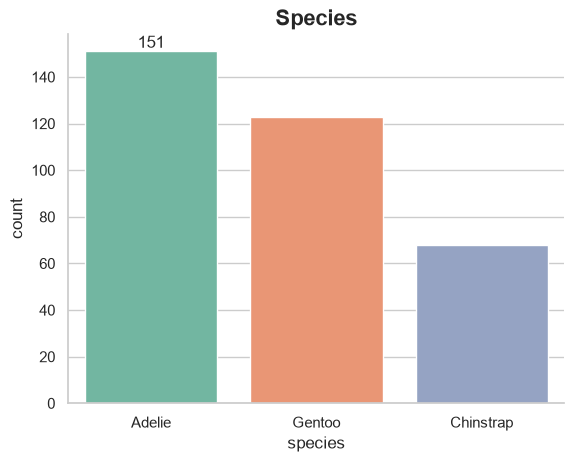

In [13]:
sns.set_theme(style='whitegrid')
ax = sns.countplot(data=df, x='species', palette='Set2', order=df['species'].value_counts().index)
ax.bar_label(ax.containers[0])
ax.set_title('Species', fontsize=16, fontweight='bold')
sns.despine()
plt.show()

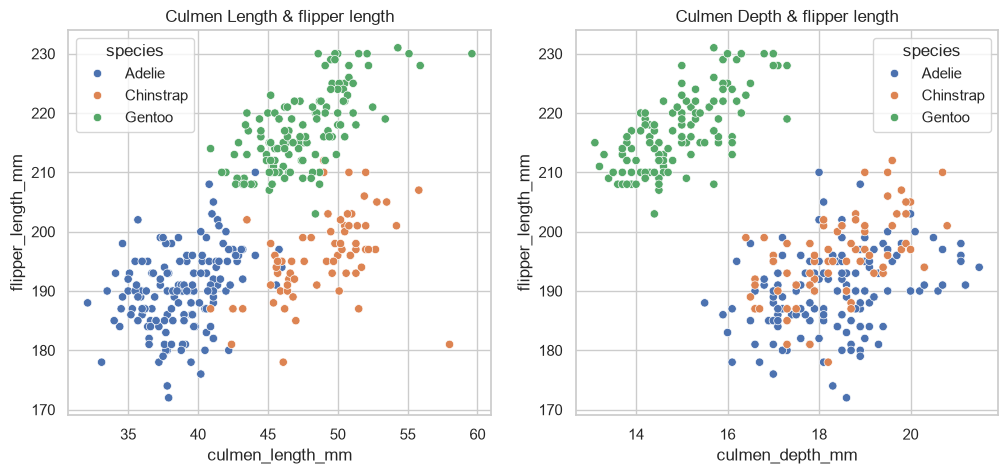

In [14]:
fig , ax = plt.subplots(1,2, figsize=(12,5))

sns.scatterplot(x=df["culmen_length_mm"],y=df["flipper_length_mm"],ax=ax[0],hue=df["species"])
sns.scatterplot(x=df["culmen_depth_mm"],y=df["flipper_length_mm"],ax=ax[1],hue=df["species"])
ax[0].set_title("Culmen Length & flipper length")
ax[1].set_title("Culmen Depth & flipper length")
plt.show()

<Axes: >

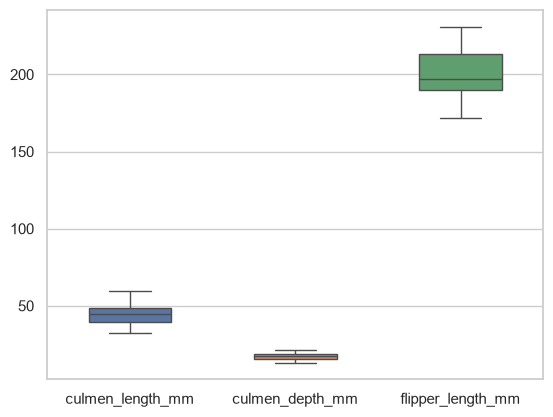

In [15]:
df_box = df[['culmen_length_mm', 'culmen_depth_mm','flipper_length_mm']]
sns.boxplot(data=df_box, width=0.5,fliersize=5)

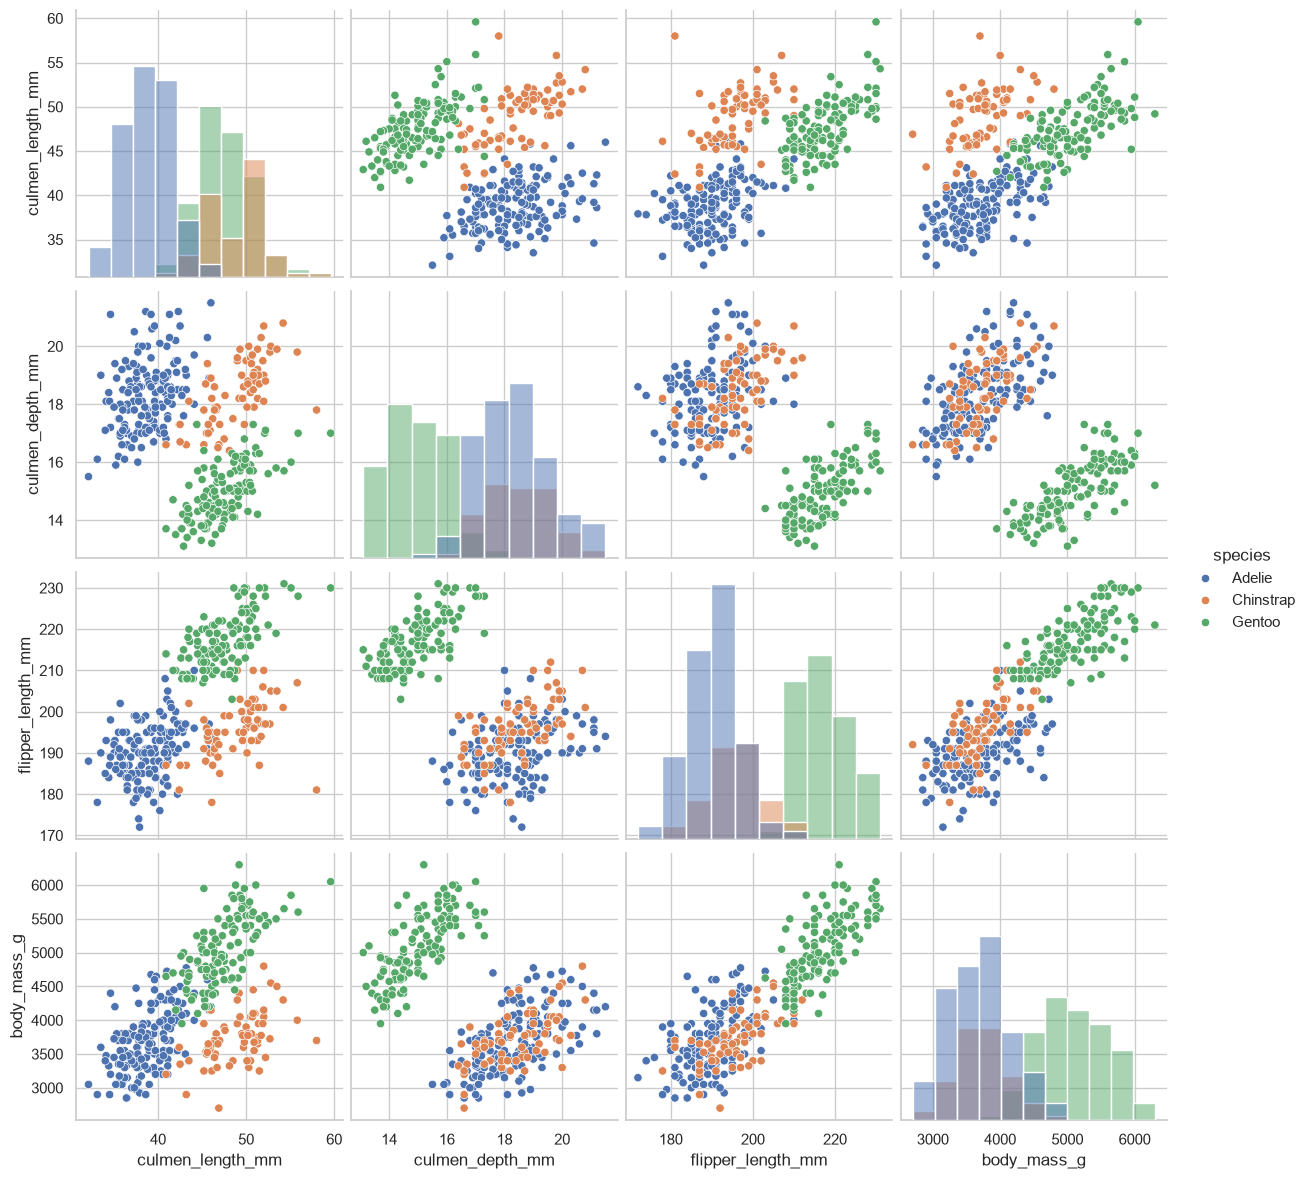

In [16]:
sns.pairplot(df, hue="species", height=3,diag_kind="hist")

## ENCODING

In [17]:
##Female and male were changed to 0 and 1.
df["sex"] = df["sex"].map({"FEMALE": 0, "MALE": 1})

print(df["sex"].value_counts())

sex
0    172
1    170
Name: count, dtype: int64


In [18]:
le = LabelEncoder()
y = le.fit_transform(df["species"])        # Adelie=0, Chinstrap=1, Gentoo=2
print(le.classes_)                 

['Adelie' 'Chinstrap' 'Gentoo']


In [19]:
df = pd.get_dummies(df, columns=["island"],  dtype=int) # one-hot encoding

## STANDARTIZATION

In [20]:
X = df.drop(columns=["species"])

X_train , X_test , y_train , y_test = train_test_split(X,y,test_size=0.2, random_state=42,stratify=y)

num_cols = ["culmen_length_mm", "culmen_depth_mm",
            "flipper_length_mm", "body_mass_g"]

scaler = StandardScaler()
X_train = X_train.copy(); X_test = X_test.copy()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [21]:
print(X_train.shape,X_test.shape)
print(X_train.isna().sum().sum())
print(X_train.dtypes)

(273, 8) (69, 8)
0
culmen_length_mm     float64
culmen_depth_mm      float64
flipper_length_mm    float64
body_mass_g          float64
sex                    int64
island_Biscoe          int64
island_Dream           int64
island_Torgersen       int64
dtype: object


In [22]:
X_train_t = torch.tensor(X_train.values, dtype=torch.float32)
X_test_t  = torch.tensor(X_test.values,  dtype=torch.float32)

y_train_t = torch.tensor(y_train, dtype=torch.long)
y_test_t  = torch.tensor(y_test,  dtype=torch.long)

## MODEL TRAINING

In [23]:
class PenguinModel(nn.Module):
    def __init__(self):
        super().__init__()
            
        self.layer1 = nn.Linear(in_features=8, out_features=16)
        self.layer2 = nn.Linear(in_features=16, out_features=16)
        self.layer3 = nn.Linear(in_features=16, out_features=3)
        
        self.relu = nn.ReLU()
        
    def forward(self,x):
        x = self.relu(self.layer1(x))
        x = self.relu(self.layer2(x))
        return self.layer3(x)

In [24]:
model = PenguinModel()
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(),lr=0.01)

In [25]:
def calculate_accuracy(y_true,y_pred):
    correct = torch.eq(y_true,y_pred).sum().item()
    acc = (correct / len(y_pred)) * 100
    return acc

In [27]:
epochs = 200

train_losses = []
test_losses = []
test_accurecies = []
train_accurecies = []

for epoch in range(epochs):
    
    model.train()
    
    logits = model(X_train_t)
    loss = loss_fn(logits, y_train_t)
    
    pred = torch.softmax(logits , dim = 1).argmax(dim=1)
    acc = calculate_accuracy(y_train_t,pred)
    
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    train_losses.append(loss.item())
    train_accurecies.append(acc)
    
    model.eval()
    with torch.inference_mode():
        test_logits = model(X_test_t)
        test_loss = loss_fn(test_logits,y_test_t)
        test_pred = torch.softmax(test_logits, dim=1).argmax(dim=1)
        test_acc = calculate_accuracy(y_test_t,test_pred)
    test_losses.append(test_loss.item())
    test_accurecies.append(test_acc)
    
    if epoch % 20 == 0:
         print(f"Epoch {epoch} | Loss: {loss:.4f} | Acc: {acc:.2f}% | "
              f"Test Loss: {test_loss:.4f} | Test Acc: {test_acc:.2f}%")

Epoch 0 | Loss: 1.1111 | Acc: 21.98% | Test Loss: 1.0765 | Test Acc: 42.03%
Epoch 20 | Loss: 0.3239 | Acc: 80.22% | Test Loss: 0.3182 | Test Acc: 79.71%
Epoch 40 | Loss: 0.0475 | Acc: 98.90% | Test Loss: 0.0399 | Test Acc: 100.00%
Epoch 60 | Loss: 0.0105 | Acc: 99.63% | Test Loss: 0.0018 | Test Acc: 100.00%
Epoch 80 | Loss: 0.0061 | Acc: 100.00% | Test Loss: 0.0005 | Test Acc: 100.00%
Epoch 100 | Loss: 0.0043 | Acc: 100.00% | Test Loss: 0.0003 | Test Acc: 100.00%
Epoch 120 | Loss: 0.0032 | Acc: 100.00% | Test Loss: 0.0002 | Test Acc: 100.00%
Epoch 140 | Loss: 0.0024 | Acc: 100.00% | Test Loss: 0.0002 | Test Acc: 100.00%
Epoch 160 | Loss: 0.0019 | Acc: 100.00% | Test Loss: 0.0001 | Test Acc: 100.00%
Epoch 180 | Loss: 0.0014 | Acc: 100.00% | Test Loss: 0.0001 | Test Acc: 100.00%


## Model evaluation

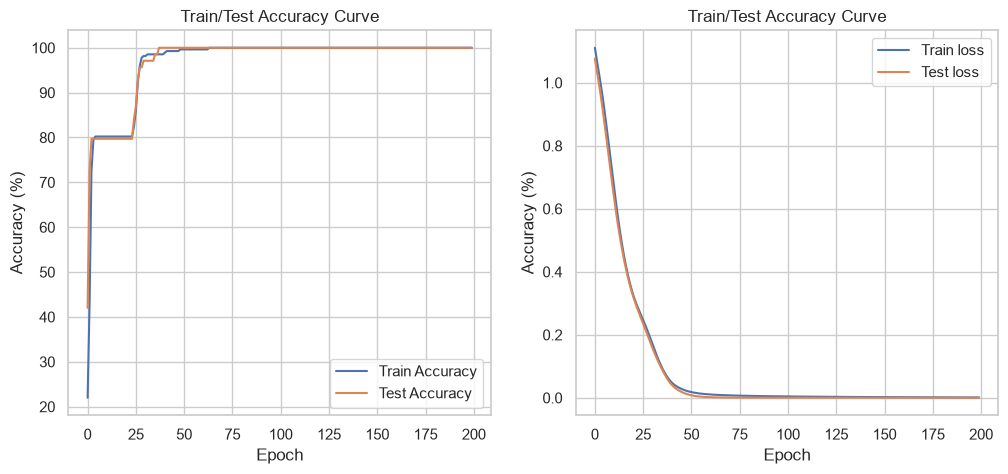

In [28]:
fig , ax = plt.subplots(1,2, figsize=(12,5))
ax[0].plot(train_accurecies, label="Train Accuracy")
ax[0].plot(test_accurecies, label="Test Accuracy")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Accuracy (%)")
ax[0].set_title("Train/Test Accuracy Curve")

ax[0].legend()

ax[1].plot(train_losses, label="Train loss")
ax[1].plot(test_losses, label="Test loss")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Accuracy (%)")
ax[1].set_title("Train/Test Accuracy Curve")

ax[1].legend()
plt.show()

In [29]:
from torchmetrics.classification import MulticlassConfusionMatrix

cm = MulticlassConfusionMatrix(num_classes=3)

matrix = cm(test_pred,y_test_t)

print(matrix)

tensor([[30,  0,  0],
        [ 0, 14,  0],
        [ 0,  0, 25]])


## Model serialization / saving a checkpoint

In [30]:
from pathlib import Path

MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True,exist_ok=True)

MODEL_NAME = "penguin_model.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME
torch.save(obj=model.state_dict(),f=MODEL_SAVE_PATH)

In [31]:
import joblib

joblib.dump(scaler, MODEL_PATH / "scaler.pkl")
joblib.dump(le, MODEL_PATH / "label_encoder.pkl")
joblib.dump(list(X_train.columns), MODEL_PATH / "columns.pkl")

['models\\columns.pkl']